# Book-Crossing Recommender
Data Mining Lab Assignment-2

Name: Ansh Bhargava

Roll No: LCB2023012

In [1]:
import csv
import io
import subprocess
import sys
from importlib.util import find_spec
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix, load_npz, save_npz
from sklearn.metrics.pairwise import cosine_similarity

if find_spec("pyarrow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow"])

In [2]:
bronze = Path("bronze")
silver = Path("silver")
gold = Path("gold")

for folder in (bronze, silver, gold):
    folder.mkdir(exist_ok=True)

archive = Path("book-crossings.zip")

In [3]:
sources = {"users": "BX-Users.csv", "books": "BX-Books.csv", "ratings": "BX-Book-Ratings.csv"}
ingested_at = pd.Timestamp.now(tz="UTC").floor("us")
with ZipFile(archive) as dataset:
    for name, filename in sources.items():
        with io.TextIOWrapper(dataset.open(filename), encoding="latin-1", newline="") as source:
            rows = csv.reader(source, delimiter=";", escapechar="\\", strict=True)
            frame = pd.DataFrame(rows, columns=next(rows), dtype="string")
        frame.assign(ingestion_timestamp=ingested_at).to_parquet(bronze / f"{name}.parquet", index=False)
del frame

## 1. Bronze — EDA

### Table sizes, data types and missing values

In [4]:
raw = {name: pd.read_parquet(bronze / f"{name}.parquet") for name in sources}
for name, frame in raw.items():
    print(f"{name.title()}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")
    missing = (frame.isna() | frame.isin(["NULL", ""])).sum()
    display(pd.DataFrame({"dtype": frame.dtypes.astype(str), "missing": missing}))

Users: 278,858 rows × 4 columns


,dtype,missing
User-ID,string,0
Location,string,0
Age,string,110762
ingestion_timestamp,"datetime64[us, UTC]",0


Books: 271,379 rows × 9 columns


,dtype,missing
ISBN,string,0
Book-Title,string,0
Book-Author,string,0
Year-Of-Publication,string,0
Publisher,string,0
Image-URL-S,string,0
Image-URL-M,string,0
Image-URL-L,string,0
ingestion_timestamp,"datetime64[us, UTC]",0


Ratings: 1,149,780 rows × 4 columns


,dtype,missing
User-ID,string,0
ISBN,string,0
Book-Rating,string,0
ingestion_timestamp,"datetime64[us, UTC]",0


### Rating, age and publication-year distributions

,count
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


Ages outside 5–100: 1,248
Publication years: 4,619 zero, 11 future


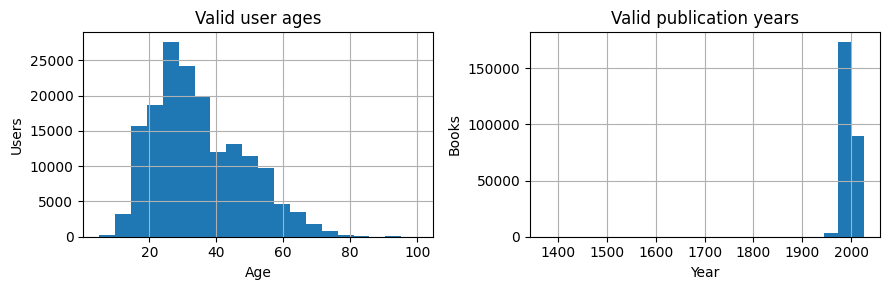

In [5]:
scores = pd.to_numeric(raw["ratings"]["Book-Rating"])
ages = pd.to_numeric(raw["users"]["Age"], errors="coerce")
years = pd.to_numeric(raw["books"]["Year-Of-Publication"], errors="coerce")
current_year = pd.Timestamp.now(tz="UTC").year

display(scores.value_counts().sort_index().rename("count").to_frame())
print(f"Ages outside 5–100: {(ages.notna() & ~ages.between(5, 100)).sum():,}")
print(f"Publication years: {years.eq(0).sum():,} zero, {years.gt(current_year).sum():,} future")
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
ages[ages.between(5, 100)].hist(ax=axes[0], bins=20)
years[years.between(1, current_year)].hist(ax=axes[1], bins=24)
axes[0].set(title="Valid user ages", xlabel="Age", ylabel="Users")
axes[1].set(title="Valid publication years", xlabel="Year", ylabel="Books")
plt.tight_layout()
plt.show()

### Rating counts and sparsity

In [6]:
pairs = raw["ratings"][["User-ID", "ISBN"]]
linked = pairs["User-ID"].isin(raw["users"]["User-ID"]) & pairs["ISBN"].isin(raw["books"]["ISBN"])
explicit = pairs.loc[linked & scores.between(1, 10)].drop_duplicates()
min_ratings = 10
for key in ("User-ID", "ISBN"):
    counts = pairs[key].value_counts()
    below_min = (counts < min_ratings).mean()
    explicit_counts = explicit[key].value_counts()
    print(f"{key}: median {counts.median():g} interactions, {below_min:.1%} below {min_ratings}")
    print(f"  {(explicit_counts >= min_ratings).sum():,} with at least {min_ratings} linked explicit ratings")

possible = len(raw["users"]) * len(raw["books"])
print(f"All linked interactions: {len(pairs.loc[linked].drop_duplicates()) / possible:.6%} filled")
print(f"Explicit ratings: {len(explicit) / possible:.6%} filled, {1 - len(explicit) / possible:.6%} empty")

User-ID: median 1 interactions, 87.6% below 10
  6,589 with at least 10 linked explicit ratings
ISBN: median 1 interactions, 94.6% below 10
  5,444 with at least 10 linked explicit ratings
All linked interactions: 0.001363% filled
Explicit ratings: 0.000507% filled, 99.999493% empty


## 2. Silver — Cleaning



In [7]:
def clean_table(name, columns):
    table = raw[name][list(columns)].drop_duplicates()
    return table.rename(columns=columns)

def clean_text(column):
    return column.str.replace(r"\s+", " ", regex=True).str.strip()

### Clean ages and split locations

In [8]:
users = clean_table("users", {"User-ID": "user_id", "Age": "age", "Location": "location"})
users["user_id"] = users["user_id"].astype(int)
age = pd.to_numeric(users["age"], errors="coerce")
age = age.where(age.between(5, 100))
users["age"] = age.fillna(age.median())

location = users.pop("location").str.rsplit(",", n=2)
users["city"] = location.str[0]
users["state"] = location.str[1].where(location.str.len().eq(3))
users["country"] = location.str[-1].where(location.str.len().ge(2))
for column in ("city", "state", "country"):
    users[column] = clean_text(users[column]).str.casefold().replace(["", "n/a", '"n/a"'], pd.NA)

### Clean book details

In [9]:
books = clean_table("books", {
    "ISBN": "book_id", "Book-Title": "title", "Book-Author": "author",
    "Year-Of-Publication": "year", "Publisher": "publisher",
})
for column in ("title", "author", "publisher"):
    books[column] = clean_text(books[column])
books["publisher"] = books["publisher"].str.casefold()
books["title_key"] = books["title"].str.casefold()
book_years = pd.to_numeric(books["year"], errors="coerce")
books["year"] = book_years.where(book_years.between(1, current_year)).astype("Int64")

### Keep valid ratings

In [10]:
interactions = clean_table("ratings", {"User-ID": "user_id", "ISBN": "book_id", "Book-Rating": "rating"})
interactions = interactions.astype({"user_id": int, "rating": int})
known_user = interactions["user_id"].isin(users["user_id"])
known_book = interactions["book_id"].isin(books["book_id"])
interactions = interactions[known_user & known_book]
ratings = interactions[interactions["rating"].between(1, 10)]
ratings = ratings.groupby(["user_id", "book_id"], as_index=False)["rating"].mean()

### Apply the minimum rating count

In [11]:
while True:
    user_count = ratings.groupby("user_id")["rating"].transform("size")
    book_count = ratings.groupby("book_id")["rating"].transform("size")
    keep = user_count.ge(min_ratings) & book_count.ge(min_ratings)
    if keep.all():
        break
    ratings = ratings[keep]

### Save the cleaned tables and reading history

In [12]:
users = users[users["user_id"].isin(ratings["user_id"])].sort_values("user_id")
history = interactions.loc[interactions["user_id"].isin(users["user_id"]), ["user_id", "book_id"]]
history = history.merge(books[["book_id", "title_key"]], on="book_id")
history = history[["user_id", "title_key"]].drop_duplicates()
books = books[books["book_id"].isin(ratings["book_id"])].sort_values("book_id")

for name, frame in {"users": users, "books": books, "ratings": ratings, "history": history}.items():
    frame.to_parquet(silver / f"{name}.parquet", index=False)
    print(f"{name.title()}: {len(frame):,} rows")

Users: 1,820 rows
Books: 2,030 rows
Ratings: 41,456 rows
History: 474,257 rows


## 3. Gold — Build the rating matrix

### Build and save the sparse matrix

In [13]:
users, books, ratings, history = (
    pd.read_parquet(silver / f"{name}.parquet") for name in ("users", "books", "ratings", "history")
)
user_ids = pd.Index(users["user_id"])
book_ids = pd.Index(books["book_id"])
rows = user_ids.get_indexer(ratings["user_id"])
columns = book_ids.get_indexer(ratings["book_id"])
matrix = csr_matrix((ratings["rating"].to_numpy(dtype=float), (rows, columns)),
                    shape=(len(user_ids), len(book_ids)))
save_npz(gold / "user_book_ratings.npz", matrix)

### Save lookup tables and rating summaries

In [14]:
users[["user_id"]].to_parquet(gold / "user_index.parquet", index=False)
books[["book_id", "title", "author", "title_key"]].to_parquet(gold / "book_lookup.parquet", index=False)
history[history["title_key"].isin(books["title_key"])].to_parquet(gold / "history.parquet", index=False)

for key, name in (("user_id", "user"), ("book_id", "book")):
    summary = ratings.groupby(key)["rating"].agg(average_rating="mean", rating_count="size")
    summary.reset_index().to_parquet(gold / f"{name}_aggregates.parquet", index=False)

print(f"{matrix.shape[0]:,} users × {matrix.shape[1]:,} books, {matrix.nnz:,} explicit ratings")

1,820 users × 2,030 books, 41,456 explicit ratings


## 4. Find similar books and recommend titles

### Load the Gold data

In [15]:
matrix = load_npz(gold / "user_book_ratings.npz")
book_ratings = matrix.T.tocsr()
user_ids = pd.read_parquet(gold / "user_index.parquet")["user_id"]
user_rows = pd.Series(user_ids.index, index=user_ids)
books = pd.read_parquet(gold / "book_lookup.parquet")
history = pd.read_parquet(gold / "history.parquet").set_index("user_id")["title_key"]
book_counts = pd.read_parquet(gold / "book_aggregates.parquet").set_index("book_id")["rating_count"]
books["rating_count"] = books["book_id"].map(book_counts)
high_rating = 8

### Rank the results

In [16]:
def top_books(scores, skip_titles, n):
    results = books.assign(score=scores)
    results = results[results["score"] > 0]
    results = results[~results["title_key"].isin(skip_titles)]
    results = results.sort_values(["score", "rating_count", "book_id"], ascending=[False, False, True])
    results = results.drop_duplicates("title_key")
    return results[["title", "author", "score"]].head(max(n, 0)).reset_index(drop=True)

### Find books similar to a title

In [17]:
def similar_books(title):
    key = " ".join(title.split()).casefold()
    matches = books[books["title_key"] == key]
    if matches.empty:
        raise ValueError(f"Unknown book: {title}")
    book_row = matches["rating_count"].idxmax()
    scores = cosine_similarity(book_ratings, book_ratings[[book_row]])[:, 0]
    return top_books(scores, [key], 10)

### Recommend books for a user

In [18]:
def recommend(user_id, n=10):
    if user_id not in user_rows:
        raise ValueError(f"Unknown user: {user_id}")
    user_ratings = matrix.getrow(user_rows.loc[user_id])
    liked = user_ratings.data >= high_rating
    favorite_books = user_ratings.indices[liked]
    if len(favorite_books) == 0:
        return top_books(np.zeros(len(books)), [], n)

    similarities = cosine_similarity(book_ratings, book_ratings[favorite_books])
    scores = np.average(similarities, axis=1, weights=user_ratings.data[liked])
    return top_books(scores, history.loc[[user_id]], n)

## 5. Try the recommender

### Check the minimum rating count

In [19]:
pd.set_option("display.max_colwidth", None)
assert matrix.getnnz(axis=0).min() >= min_ratings
assert matrix.getnnz(axis=1).min() >= min_ratings

### Show recommendations for three readers

In [22]:
for user_id in [7841, 11601, 12824]:
    user_ratings = matrix.getrow(user_rows.loc[user_id])
    liked = user_ratings.data >= high_rating
    favorites = books.loc[user_ratings.indices[liked], ["title"]].copy()
    favorites["rating"] = user_ratings.data[liked]
    favorites = favorites.sort_values(["rating", "title"], ascending=[False, True])
    favorites.columns = ["Highly rated title", "User rating"]

    suggestions = recommend(user_id)
    assert len(suggestions) == 10
    assert suggestions["score"].is_monotonic_decreasing
    assert set(suggestions["title"].str.casefold()).isdisjoint(history.loc[[user_id]])
    suggestions = suggestions[["title", "score"]].round(4)
    suggestions.columns = ["Recommended title", "Weighted cosine"]

    print(f"User {user_id}")
    display(pd.concat([favorites.reset_index(drop=True), suggestions], axis=1))

User 7841


,Highly rated title,User rating,Recommended title,Weighted cosine
0,On the Road (Penguin 20th Century Classics),10.0,The World According to Garp,0.0893
1,The Things They Carried,10.0,Waiting (Vintage International),0.0876
2,The Woman Warrior : Memoirs of a Girlhood Among Ghosts,10.0,Confessions of an Ugly Stepsister : A Novel,0.0870
3,Into the Wild,9.0,Bastard Out of Carolina,0.0841
4,One Flew Over the Cuckoo's Nest,9.0,Island of the Blue Dolphins (Laurel Leaf Books),0.0839
5,The House on Mango Street (Vintage Contemporaries),9.0,Charlie and the Chocolate Factory (Puffin Novels),0.0832
6,Where the Red Fern Grows,9.0,The Temple of My Familiar,0.0829
7,Wicked: The Life and Times of the Wicked Witch of the West,9.0,Patty Jane's House of Curl (Ballantine Reader's Circle),0.0776
8,Matilda,8.0,The Return of the Indian (Indian in the Cupboard),0.0776
9,Speaker for the Dead (Ender Wiggins Saga (Paperback)),8.0,Empire Falls,0.0770


User 11601


,Highly rated title,User rating,Recommended title,Weighted cosine
0,A Virtuous Woman (Oprah's Book Club (Paperback)),10.0,The Cat in the Hat,0.0788
1,Fast Food Nation: The Dark Side of the All-American Meal,10.0,The Lovely Bones: A Novel,0.0724
2,Green Eggs and Ham (I Can Read It All by Myself Beginner Books),10.0,YOU BELONG TO ME,0.0696
3,Johnny Got His Gun,10.0,A Short Guide to a Happy Life,0.0690
4,"ROAD LESS TRAVELED : A New Psychology of Love, Traditional Values, and Spritual Growth (Touchstone Books (Paperback))",10.0,Mixed Blessings,0.0670
5,The Bean Trees,10.0,She's Come Undone (Oprah's Book Club (Paperback)),0.0660
6,The Color of Water: A Black Man's Tribute to His White Mother,10.0,I Know This Much Is True (Oprah's Book Club),0.0659
7,To Kill a Mockingbird,10.0,What We Keep : A Novel (Ballantine Reader's Circle),0.0654
8,I'll Be Seeing You,9.0,Hanna's Daughters (Ballantine Reader's Circle),0.0646
9,MOONLIGHT BECOMES YOU,8.0,Possessing the Secret of Joy,0.0634


User 12824


,Highly rated title,User rating,Recommended title,Weighted cosine
0,Harry Potter and the Prisoner of Azkaban (Book 3),10.0,The Stand (The Complete and Uncut Edition),0.1297
1,"The Lion, the Witch and the Wardrobe (rpkg) (Narnia)",10.0,Desperation,0.1257
2,BAG OF BONES : A NOVEL,9.0,Needful Things: The Last Castle Rock Story,0.1121
3,Blood and Gold (Vampire Chronicles),8.0,Harry Potter and the Goblet of Fire (Book 4),0.1116
4,Dark Paradise,8.0,Rose Madder,0.1068
5,Four Past Midnight,8.0,Dolores Claiborne,0.0982
6,Hannibal,8.0,"The Drawing of the Three (The Dark Tower, Book 2)",0.0967
7,Harry Potter and the Chamber of Secrets (Book 2),8.0,"Wizard and Glass (The Dark Tower, Book 4)",0.0967
8,Neverwhere,8.0,The Green Mile: The Complete Serial Novel,0.0965
9,Red Dragon,8.0,The Girl Who Loved Tom Gordon : A Novel,0.0948


### Try a book title

In [21]:
title = "The Lovely Bones: A Novel"
neighbors = similar_books(title)
assert len(neighbors) == 10 and neighbors["score"].is_monotonic_decreasing
print(f"Ten books similar to {title!r}")
display(neighbors.round(4))

Ten books similar to 'The Lovely Bones: A Novel'


,title,author,score
0,Where the Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.2192
1,Lucky : A Memoir,Alice Sebold,0.2180
2,The Da Vinci Code,Dan Brown,0.1783
3,The Pilot's Wife : A Novel,Anita Shreve,0.1763
4,Good in Bed,Jennifer Weiner,0.1758
5,Nights in Rodanthe,Nicholas Sparks,0.1702
6,The Pact: A Love Story,Jodi Picoult,0.1682
7,The Lake House,James Patterson,0.1662
8,Lucky,Alice Sebold,0.1651
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.1542
